In [ ]:
# Общие импорты и локальные данные JERICHON
import os, sys
from pathlib import Path

_HERE = Path(globals().get("__vsc_ipynb_file__", Path.cwd())).expanduser().resolve()
_CANDIDATES = [_HERE, *_HERE.parents, Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in dict.fromkeys(_CANDIDATES)
                     if (p / "src" / "data" / "load_data.py").is_file()
                     and (p / "research").is_dir()), None)
if PROJECT_ROOT is None and os.environ.get("JERICHON_PROJECT_ROOT"):
    PROJECT_ROOT = Path(os.environ["JERICHON_PROJECT_ROOT"]).expanduser().resolve()
if PROJECT_ROOT is None or not (PROJECT_ROOT / "src" / "data" / "load_data.py").is_file():
    raise FileNotFoundError("Не найден корень JERICHON с src/data/load_data.py")
sys.path[:0] = [str(PROJECT_ROOT), str(PROJECT_ROOT / "data")]
from src.data.load_data import *
ROOT = PROJECT_ROOT


In [1]:
import mplcyberpunk
import matplotlib.pyplot as plt
plt.style.use('cyberpunk')

import sys
from pathlib import Path
import pandas as pd
import numpy as np
import logging
import matplotlib.dates as mdates
import joblib
from datetime import datetime

ROOT = PROJECT_ROOT / "data"
if str(ROOT.parent) not in sys.path:
    sys.path.insert(0, str(ROOT.parent))
logging.basicConfig(level=logging.WARNING)
logger = logging.getLogger("research")
from src.data.builders.dollar_bars import InformationDrivenBars
from src.data.labeling.cusum import cusum_filter
from src.data.labeling.triple_barrier import triple_barrier_labeling
from src.data.builders.micro_features import MicroFeatures
from src.data.builders.build_features import FeatureBuilder

from collections import defaultdict
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
import optuna
from tqdm import tqdm

import itertools
import warnings
warnings.filterwarnings('ignore')

In [10]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = PROJECT_ROOT
from src.data.providers.algopack_provider import AlgoPackProvider

ticker = "MGNT"
base = HISTORY_ROOT / "realtime" / ticker
files = sorted(base.glob("*/trades.parquet"), reverse=True)
print(f"Найдено файлов: {len(files)}")
for f in files:
    print(f"  {f}")

if not files:
    print("ФАКАП: файлов нет!")
else:
    raw = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
    print(f"\nСырых сделок: {len(raw)}")
    print(f"Колонки: {list(raw.columns)}")
    print(f"VALUE sum: {pd.to_numeric(raw.get('VALUE'), errors='coerce').sum():,.2f}")
    print(f"VALUE NaN count: {raw['VALUE'].isna().sum()}")
    print(f"VALUE <= 0 count: {(pd.to_numeric(raw['VALUE'], errors='coerce') <= 0).sum()}")

    provider = AlgoPackProvider(mock=True)
    norm = provider._normalize_trades(raw, ticker)
    print(f"\nПосле нормализации: {len(norm)}")
    print(f"Колонки: {list(norm.columns)}")
    print(f"value NaN: {norm['value'].isna().sum()}")
    print(f"value <= 0: {(norm['value'] <= 0).sum()}")
    print(f"value sum: {norm['value'].sum():,.2f}")
    print(f"price NaN: {norm['price'].isna().sum()}")
    print(f"\nПервые 5 строк value: {norm['value'].head().tolist()}")

Найдено файлов: 2
  C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history\realtime\MGNT\2026-08-31\trades.parquet
  C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history\realtime\MGNT\2026-08-28\trades.parquet

Сырых сделок: 114985
Колонки: ['TRADENO', 'TRADETIME', 'PRICE', 'QUANTITY', 'PERIOD', 'VALUE', 'BUYSELL', 'DECIMALS', 'TRADINGSESSION', 'TRADEDATE', 'TRADE_SESSION_DATE', 'ts', 'ticker']
VALUE sum: 5,786,589,337.50
VALUE NaN count: 0
VALUE <= 0 count: 0

После нормализации: 114985
Колонки: ['TRADENO', 'TRADETIME', 'PRICE', 'QUANTITY', 'PERIOD', 'VALUE', 'BUYSELL', 'DECIMALS', 'TRADINGSESSION', 'TRADEDATE', 'TRADE_SESSION_DATE', 'ts', 'ticker', 'trade_id', 'price', 'quantity', 'value', 'side']
value NaN: 0
value <= 0: 0
value sum: 5,786,589,337.50
price NaN: 0

Первые 5 строк value: [1491.5, 238640.0, 2983.0, 1491.5, 447450.0]


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np

TICKER = "MAGN"
DATE = "2026-08-19"

ROOT = PROJECT_ROOT
trades_path = (
    HISTORY_ROOT
    / "realtime"
    / TICKER
    / DATE
    / "trades.parquet"
)

candles_path = (
    HISTORY_ROOT
    / "realtime"
    / TICKER
    / DATE
    / "candles.parquet"
)

print("=" * 80)
print("MAGN DATA FORENSICS")
print("=" * 80)

print("\nTRADES:")
print(trades_path)
print("exists:", trades_path.exists())

print("\nCANDLES:")
print(candles_path)
print("exists:", candles_path.exists())

trades = pd.read_parquet(trades_path)
candles = pd.read_parquet(candles_path)

print("\n" + "=" * 80)
print("1. SHAPES")
print("=" * 80)

print("trades :", trades.shape)
print("candles:", candles.shape)

print("\nTRADES COLUMNS:")
print(trades.columns.tolist())

print("\nCANDLES COLUMNS:")
print(candles.columns.tolist())

MAGN DATA FORENSICS

TRADES:
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history\realtime\MAGN\2026-08-19\trades.parquet
exists: True

CANDLES:
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history\realtime\MAGN\2026-08-19\candles.parquet
exists: True

1. SHAPES
trades : (13677, 13)
candles: (992, 8)

TRADES COLUMNS:
['TRADENO', 'TRADETIME', 'PRICE', 'QUANTITY', 'PERIOD', 'VALUE', 'BUYSELL', 'DECIMALS', 'TRADINGSESSION', 'TRADEDATE', 'TRADE_SESSION_DATE', 'ts', 'ticker']

CANDLES COLUMNS:
['open', 'close', 'high', 'low', 'value', 'volume', 'ts', 'ticker']


In [4]:
print("\n" + "=" * 80)
print("2. TRADES SAMPLE")
print("=" * 80)

print(trades.head(10).to_string())

print("\n" + "=" * 80)
print("3. CANDLES SAMPLE")
print("=" * 80)

print(candles.head(10).to_string())


2. TRADES SAMPLE
       TRADENO TRADETIME   PRICE  QUANTITY PERIOD      VALUE BUYSELL  DECIMALS  TRADINGSESSION   TRADEDATE TRADE_SESSION_DATE                        ts ticker
0  17517983615  06:59:32  20.400        10      S    2040.00       S         3               0  2026-08-19         2026-08-19 2026-08-19 06:59:32+03:00   MAGN
1  17517989898  07:00:00  20.315       100      N   20315.00       S         3               0  2026-08-19         2026-08-19 2026-08-19 07:00:00+03:00   MAGN
2  17517992798  07:00:01  20.410        39      N    7959.90       B         3               0  2026-08-19         2026-08-19 2026-08-19 07:00:01+03:00   MAGN
3  17517994368  07:00:02  20.395        64      N   13052.80       S         3               0  2026-08-19         2026-08-19 2026-08-19 07:00:02+03:00   MAGN
4  17517994675  07:00:03  20.410       244      N   49800.40       B         3               0  2026-08-19         2026-08-19 2026-08-19 07:00:03+03:00   MAGN
5  17517996085  07:00:04  20

In [7]:
print("\n" + "=" * 80)
print("4. TURNOVER COMPARISON")
print("=" * 80)

# -------------------------
# TRADES
# -------------------------

trades["PRICE"] = pd.to_numeric(trades["PRICE"], errors="coerce")
trades["QUANTITY"] = pd.to_numeric(trades["QUANTITY"], errors="coerce")

if "VALUE" in trades.columns:
    trades["VALUE"] = pd.to_numeric(trades["VALUE"], errors="coerce")

trade_turnover_calc = (
    trades["PRICE"] * trades["QUANTITY"]
).sum()

trade_value = (
    trades["VALUE"].sum()
    if "VALUE" in trades.columns
    else np.nan
)

trade_quantity = trades["QUANTITY"].sum()

print("\nRAW TRADES")
print(f"Rows:                    {len(trades):,}")
print(f"Total quantity:          {trade_quantity:,.0f}")
print(f"PRICE × QUANTITY:        {trade_turnover_calc:,.2f}")
print(f"VALUE column:             {trade_value:,.2f}")

# -------------------------
# CANDLES
# -------------------------

candle_price = pd.to_numeric(
    candles["close"], errors="coerce"
)

candle_volume = pd.to_numeric(
    candles["volume"], errors="coerce"
)

candle_turnover = (
    candle_price * candle_volume
).sum()

print("\n1-MIN CANDLES")
print(f"Rows:                    {len(candles):,}")
print(f"Total VOLUME:            {candle_volume.sum():,.0f}")
print(f"CLOSE × VOLUME:          {candle_turnover:,.2f}")

# -------------------------
# COMPARISON
# -------------------------

print("\n" + "=" * 80)
print("COMPARISON")
print("=" * 80)

if trade_turnover_calc:
    print(
        f"Candle / trades turnover: "
        f"{candle_turnover / trade_turnover_calc:.4f}"
    )

if trade_value:
    print(
        f"VALUE / PRICE×QUANTITY: "
        f"{trade_value / trade_turnover_calc:.4f}"
    )

print(
    f"\nTrades PRICE×QUANTITY: {trade_turnover_calc:,.0f}"
)

print(
    f"Trades VALUE:          {trade_value:,.0f}"
)

print(
    f"Candles CLOSE×VOLUME:  {candle_turnover:,.0f}"
)


4. TURNOVER COMPARISON

RAW TRADES
Rows:                    13,677
Total quantity:          1,872,122
PRICE × QUANTITY:        38,897,467.22
VALUE column:             388,974,672.25

1-MIN CANDLES
Rows:                    992
Total VOLUME:            106,605,410
CLOSE × VOLUME:          2,217,251,227.50

COMPARISON
Candle / trades turnover: 57.0025
VALUE / PRICE×QUANTITY: 10.0000

Trades PRICE×QUANTITY: 38,897,467
Trades VALUE:          388,974,672
Candles CLOSE×VOLUME:  2,217,251,228


In [8]:
print("\n" + "=" * 80)
print("5. DUPLICATE TIMESTAMPS")
print("=" * 80)

ts = pd.to_datetime(trades["ts"], errors="coerce")

print("Rows:", len(trades))
print("Unique timestamps:", ts.nunique())
print("Duplicate rows by timestamp:", ts.duplicated().sum())

dups = trades.loc[
    ts.duplicated(keep=False)
].sort_values("ts")

print("\nFirst duplicated timestamps:")
print(
    dups[
        ["ts", "TRADENO", "TRADEPRICE", "QUANTITY", "VALUE"]
    ].head(30).to_string(index=False)
)


5. DUPLICATE TIMESTAMPS
Rows: 13677
Unique timestamps: 13677
Duplicate rows by timestamp: 0

First duplicated timestamps:


KeyError: "['TRADEPRICE'] not in index"

In [ ]:
# Next: NVTK, VTBR, T, MTLR
TICKER = "RUAL"

def get_available_dates(ticker: str) -> list:
    """
    Автоматически находит все доступные даты для тикера.
    Сканирует обе папки: realtime и supercandles.
    """
    dates = set()    
    # Сканируем realtime
    base_realtime = HISTORY_ROOT / "realtime" / ticker
    if base_realtime.exists():
        for date_dir in base_realtime.iterdir():
            if date_dir.is_dir():
                dates.add(date_dir.name)
    # Сканируем supercandles
    base_supercandles = HISTORY_ROOT / "supercandles" / ticker
    if base_supercandles.exists():
        for date_dir in base_supercandles.iterdir():
            if date_dir.is_dir():
                dates.add(date_dir.name)
    # Сортируем даты
    return sorted(list(dates))

def load_history(ticker: str) -> dict:
    """
    Загружает все сырые данные за все доступные даты.
    Структура: history/{realtime|supercandles}/{ticker}/{date}/{type}.parquet
    """
    result = {
        "candles": [],
        "trades": [],
        "orderbook": [],
        "tradestats": [],
        "obstats": [],
        "orderstats": [],}

    base_realtime = HISTORY_ROOT / "realtime"
    base_supercandles = HISTORY_ROOT / "supercandles"
    dates = get_available_dates(ticker)
    
    for date in dates:
        # Realtime
        rt_dir = base_realtime / ticker / date
        for key in ["candles", "trades", "orderbook"]:
            filepath = rt_dir / f"{key}.parquet"
            if filepath.exists():
                try:
                    df = pd.read_parquet(filepath)
                    df["date"] = date
                    result[key].append(df)
                except Exception as e:
                    logger.error(f"Ошибка загрузки {filepath}: {e}")

        # SuperCandles
        sc_dir = base_supercandles / ticker / date
        for key in ["tradestats", "obstats", "orderstats"]:
            filepath = sc_dir / f"{key}.parquet"
            if filepath.exists():
                try:
                    df = pd.read_parquet(filepath)
                    df["date"] = date
                    result[key].append(df)
                except Exception as e:
                    logger.error(f"Ошибка загрузки {filepath}: {e}")
    
    # Объединяем все дни
    for key in result:
        result[key] = pd.concat(result[key], ignore_index=True) if result[key] else pd.DataFrame()
    
    return result

print(f"Загрузка данных {TICKER}...\n")
data = load_history(TICKER)
# Приводим ts к datetime с московской зоной
for key, df in data.items():
    if not df.empty and 'ts' in df.columns:
        df['ts'] = pd.to_datetime(df['ts'], utc=True).dt.tz_convert('Europe/Moscow')

# Статистика
print(f"ЗАГРУЖЕНО ДАННЫХ")
for key, df in data.items():
    print(f"  {key:<12}: {len(df):>8,} записей")
print(f"\nДиапазон времени: {data['candles']['ts'].min()} — {data['candles']['ts'].max()}")
# Выводим информацию о доступных датах
available_dates = get_available_dates(TICKER)
print(f"\nДоступные даты ({len(available_dates)}):")
for date in available_dates:
    print(f"  {date}")

Загрузка данных RUAL...

ЗАГРУЖЕНО ДАННЫХ
  candles     :    9,496 записей
  trades      :  124,176 записей
  orderbook   :      180 записей
  tradestats  :    1,954 записей
  obstats     :    1,915 записей
  orderstats  :    1,973 записей

Диапазон времени: 2026-08-05 06:59:00+03:00 — 2026-08-19 23:40:00+03:00

Доступные даты (12):
  2026-08-05
  2026-08-06
  2026-08-07
  2026-08-08
  2026-08-09
  2026-08-11
  2026-08-12
  2026-08-13
  2026-08-14
  2026-08-17
  2026-08-18
  2026-08-19


▸ Построение долларовых баров...
  Используемый порог: 10,000,000 RUB
  Получено баров: 30
  Индекс уникален: True
▸ CUSUM фильтр...
  Найдено событий (до корректировки): 28
  После согласования: 28 событий


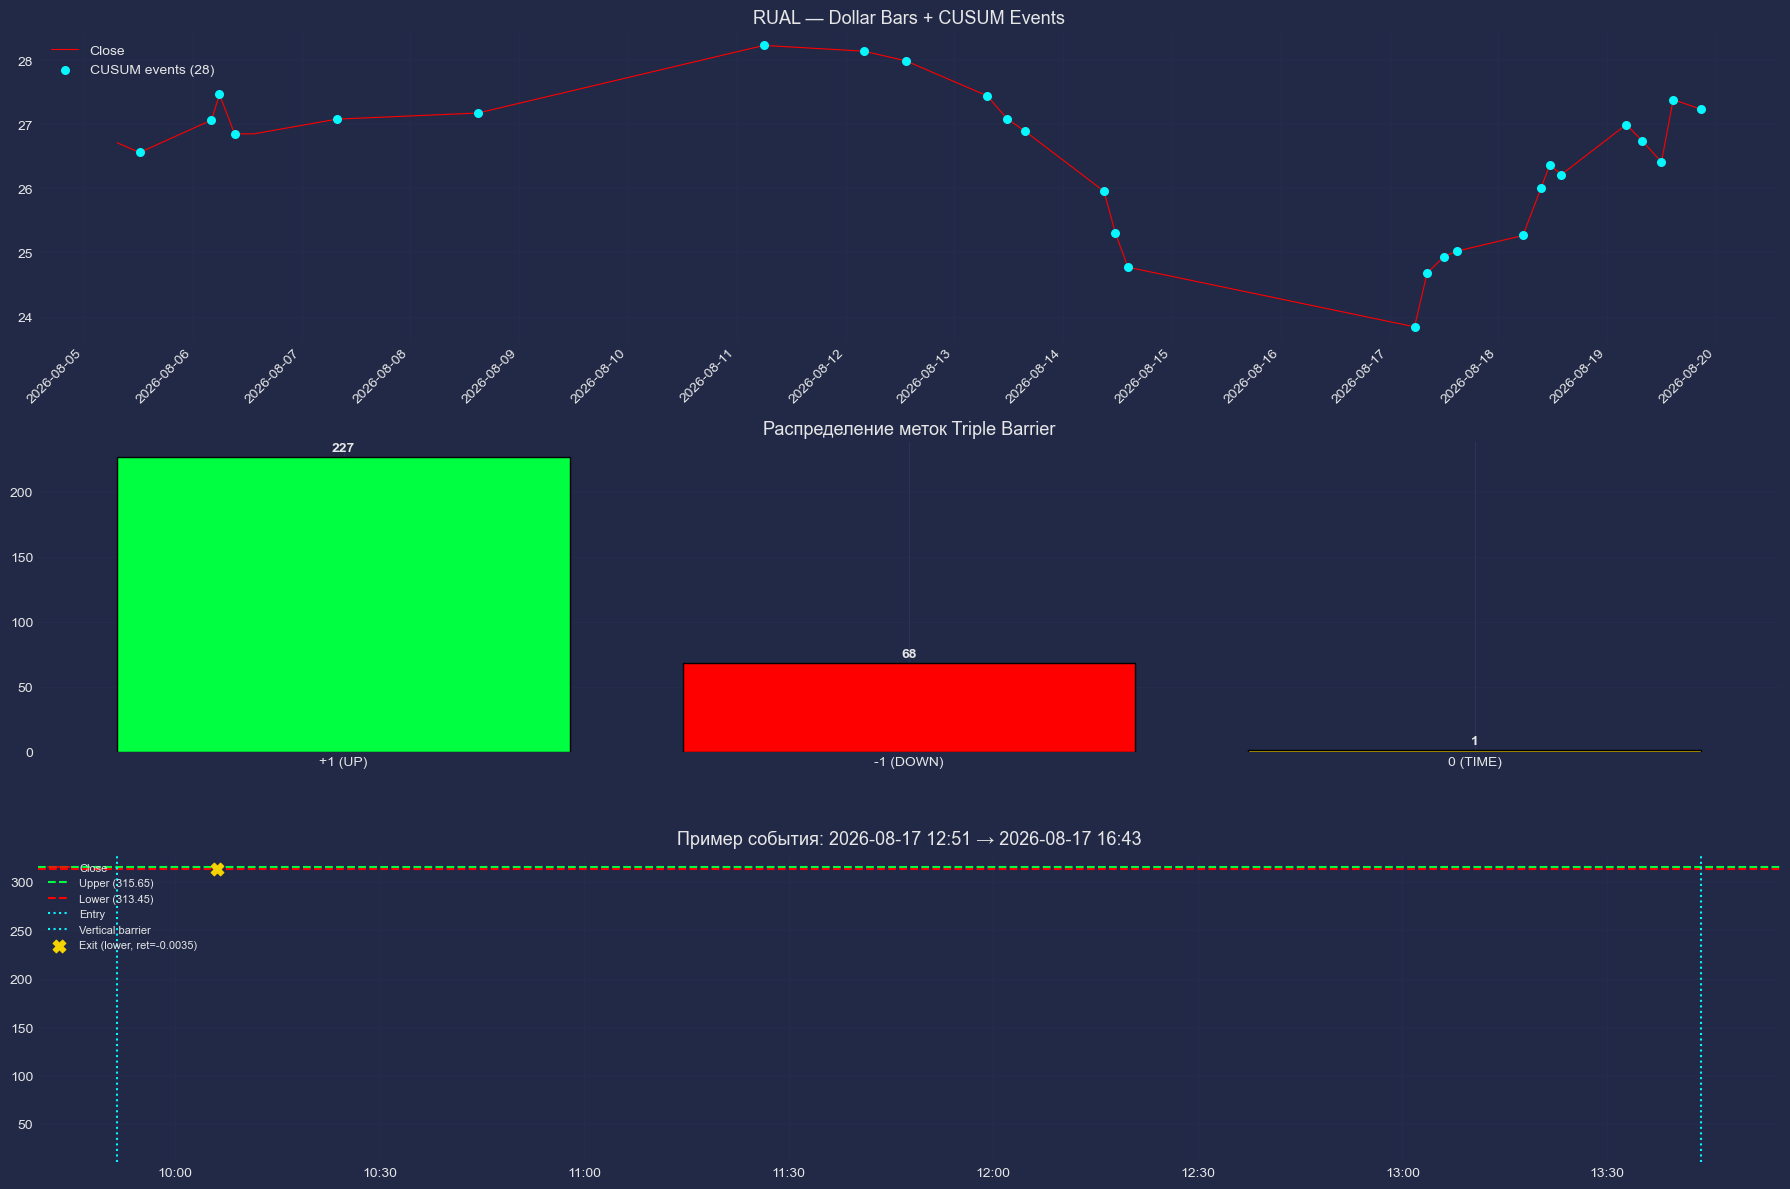

In [27]:
DOLLAR_THRESHOLD = 10_000_000  # Фиксированный порог, устанавливается пользователем
CUSUM_THRESHOLD = 0.002
PT_SL = (1.0, 1.0)
VERTICAL_BARRIER = 25
TARGET_WINDOW = 50
print("▸ Построение долларовых баров...")
trades = data["trades"].copy()

# Приведение колонок
col_map = {}
for col in trades.columns:
    if col.upper() in ["PRICE", "TRADEPRICE"]:
        col_map[col] = "price"
    elif col.upper() in ["QUANTITY", "VOLUME"]:
        col_map[col] = "quantity"
if col_map:
    trades = trades.rename(columns=col_map)
trades["ts"] = pd.to_datetime(trades["ts"])
trades = trades.dropna(subset=["price", "quantity"])

print(f"  Используемый порог: {DOLLAR_THRESHOLD:,.0f} RUB")
bar_builder = InformationDrivenBars()
dollar_bars = bar_builder.build_dollar(trades, threshold=DOLLAR_THRESHOLD)
print(f"  Получено баров: {len(dollar_bars)}")

# ===== СОЗДАЁМ ВРЕМЕННОЙ ИНДЕКС =====
dollar_bars["ts"] = dollar_bars["close_time"]
dollar_bars["ts"] = pd.to_datetime(dollar_bars["ts"])
if dollar_bars["ts"].dt.tz is None:
    dollar_bars["ts"] = dollar_bars["ts"].dt.tz_localize('Europe/Moscow')
dollar_bars = dollar_bars.set_index("ts").sort_index()
dollar_bars = dollar_bars.rename(columns={"open": "OPEN", "high": "HIGH", "low": "LOW", "close": "CLOSE", "volume": "VOLUME"})

# === ПРИНУДИТЕЛЬНОЕ ОБЕСПЕЧЕНИЕ УНИКАЛЬНОСТИ ИНДЕКСА ===
# Удаляем возможные дубликаты и NaT (это не должно удалить реальные бары, если их нет)
dollar_bars = dollar_bars[~dollar_bars.index.duplicated(keep='first')]
dollar_bars = dollar_bars[~dollar_bars.index.isna()]
print(f"  Индекс уникален: {dollar_bars.index.is_unique}")

print("▸ CUSUM фильтр...")
events_idx = cusum_filter(dollar_bars["CLOSE"], threshold=CUSUM_THRESHOLD)
print(f"  Найдено событий (до корректировки): {len(events_idx)}")

# ===== ИСПРАВЛЕННЫЙ БЛОК СОГЛАСОВАНИЯ ТАЙМЗОН =====
if len(events_idx) > 0:
    if dollar_bars.index.tz is not None:
        if events_idx.tz is None:
            events_idx = events_idx.tz_localize(dollar_bars.index.tz)
        elif events_idx.tz != dollar_bars.index.tz:
            events_idx = events_idx.tz_convert(dollar_bars.index.tz)
    else:
        if events_idx.tz is not None:
            events_idx = events_idx.tz_localize(None)
    events_idx = events_idx[~events_idx.duplicated()]
    pos = dollar_bars.index.get_indexer(events_idx, method="nearest")
    events_idx = dollar_bars.index[pos]
    events_idx = events_idx[~events_idx.duplicated()]
    events_idx = events_idx.sort_values()
    print(f"  После согласования: {len(events_idx)} событий")

# ==================================================================
# ВИЗУАЛИЗАЦИЯ
# ==================================================================
fig, axes = plt.subplots(3, 1, figsize=(18, 12))

# График 1: Бары + CUSUM
ax1 = axes[0]
ax1.plot(dollar_bars.index, dollar_bars["CLOSE"], linewidth=0.8, color="C4", label="Close")
if len(events_idx) > 0:
    ax1.scatter(events_idx, dollar_bars.loc[events_idx, "CLOSE"],
                color="C6", s=30, zorder=5, label=f"CUSUM events ({len(events_idx)})")
ax1.set_title(f"{TICKER} — Dollar Bars + CUSUM Events", fontsize=13)
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)
# Используем формат даты вместо времени
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax1.xaxis.set_major_locator(mdates.DayLocator())
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha='right')

# График 2: Распределение меток
ax2 = axes[1]
if not labeled.empty:
    colors = ["C3", "C4", "C2"]
    bars_labels = ["+1 (UP)", "-1 (DOWN)", "0 (TIME)"]
    values = [counts.get(1, 0), counts.get(-1, 0), counts.get(0, 0)]
    ax2.bar(bars_labels, values, color=colors, edgecolor="black")
    for i, v in enumerate(values):
        ax2.text(i, v + max(values)*0.02, str(v), ha="center", fontweight="bold")
ax2.set_title("Распределение меток Triple Barrier", fontsize=13)
ax2.grid(axis="y", alpha=0.3)

# График 3: Пример события с барьерами
ax3 = axes[2]
if not labeled.empty:
    sample = labeled.sample(1).iloc[0]
    evt_time = sample.name
    t1_time = sample["t1"]
    
    if not isinstance(t1_time, pd.Timestamp):
        t1_time = dollar_bars.index[t1_time] if isinstance(t1_time, int) else t1_time
    
    mask = (dollar_bars.index >= evt_time) & (dollar_bars.index <= t1_time)
    slice_bars = dollar_bars.loc[mask]
    ax3.plot(slice_bars.index, slice_bars["CLOSE"], linewidth=1.2, color="C4", label="Close")
    ax3.axhline(y=sample["upper"], color="C3", linestyle="--", label=f"Upper ({sample['upper']:.2f})")
    ax3.axhline(y=sample["lower"], color="C4", linestyle="--", label=f"Lower ({sample['lower']:.2f})")
    ax3.axvline(x=evt_time, color="C6", linestyle=":", label="Entry")
    ax3.axvline(x=t1_time, color="C6", linestyle=":", label="Vertical barrier")
    
    exit_time = sample["exit_time"]
    if not isinstance(exit_time, pd.Timestamp):
        exit_time = dollar_bars.index[exit_time] if isinstance(exit_time, int) else exit_time
    ax3.scatter(exit_time, sample["exit_price"], color="C2", s=80, zorder=5, marker="X",
                label=f"Exit ({sample['exit_type']}, ret={sample['ret']:+.4f})")
    
    ax3.set_title(f"Пример события: {evt_time.strftime('%Y-%m-%d %H:%M')} → {t1_time.strftime('%Y-%m-%d %H:%M')}", fontsize=13)
    ax3.legend(loc="upper left", fontsize=8)
    ax3.grid(True, alpha=0.3)
    # Для примера события можно оставить время, но добавить дату
    ax3.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

plt.tight_layout()
plt.show()

In [20]:
import pandas as pd
from pathlib import Path

# Корень проекта (у тебя уже есть в ноутбуке)
ROOT = PROJECT_ROOT / "data"
base = HISTORY_ROOT / "realtime" / "GAZP"

# Все папки с датами
dates = sorted([d.name for d in base.iterdir() if d.is_dir()])

print("ДАТА        | СДЕЛОК | ДИАПАЗОН ВРЕМЕНИ")
print("-" * 70)

for date in dates:
    file_path = base / date / "trades.parquet"
    if file_path.exists():
        df = pd.read_parquet(file_path)
        t_min = df['ts'].min()
        t_max = df['ts'].max()
        print(f"{date}  | {len(df):6d} | {t_min} → {t_max}")
    else:
        print(f"{date}  | ФАЙЛ НЕ НАЙДЕН")

ДАТА        | СДЕЛОК | ДИАПАЗОН ВРЕМЕНИ
----------------------------------------------------------------------
2026-08-05  |  24883 | 2026-08-06 06:59:59+03:00 → 2026-08-06 23:49:55+03:00
2026-08-06  |  22919 | 2026-08-06 06:59:52+03:00 → 2026-08-06 22:50:45+03:00
2026-08-07  |  20495 | 2026-08-07 06:59:50+03:00 → 2026-08-07 22:44:53+03:00
2026-08-08  |   5104 | 2026-08-08 09:59:48+03:00 → 2026-08-08 18:59:57+03:00
2026-08-09  |   3855 | 2026-08-09 09:59:48+03:00 → 2026-08-09 18:59:38+03:00
2026-08-11  |  12825 | 2026-08-11 06:59:33+03:00 → 2026-08-11 17:23:09+03:00
2026-08-12  |  19797 | 2026-08-12 06:59:48+03:00 → 2026-08-12 22:22:10+03:00
2026-08-13  |  22944 | 2026-08-13 06:59:53+03:00 → 2026-08-13 21:39:28+03:00
2026-08-14  |  26229 | 2026-08-14 06:59:49+03:00 → 2026-08-14 20:40:53+03:00
2026-08-17  |  27068 | 2026-08-17 06:59:31+03:00 → 2026-08-17 21:49:34+03:00
2026-08-18  |  22878 | 2026-08-18 06:59:58+03:00 → 2026-08-18 22:38:06+03:00
2026-08-19  |  18511 | 2026-08-19 06:59:55

▸ Генерация признаков...
  Всего колонок в расширенных барах: 75
  Из них числовых: 73
  Событий с полными признаками: 295
  Бинарных событий: 294 (UP: 226, DOWN: 68)
  Train: 235, Test: 59

▸ Обучение XGBoost...
Accuracy:  0.7288
ROC AUC:   0.7589


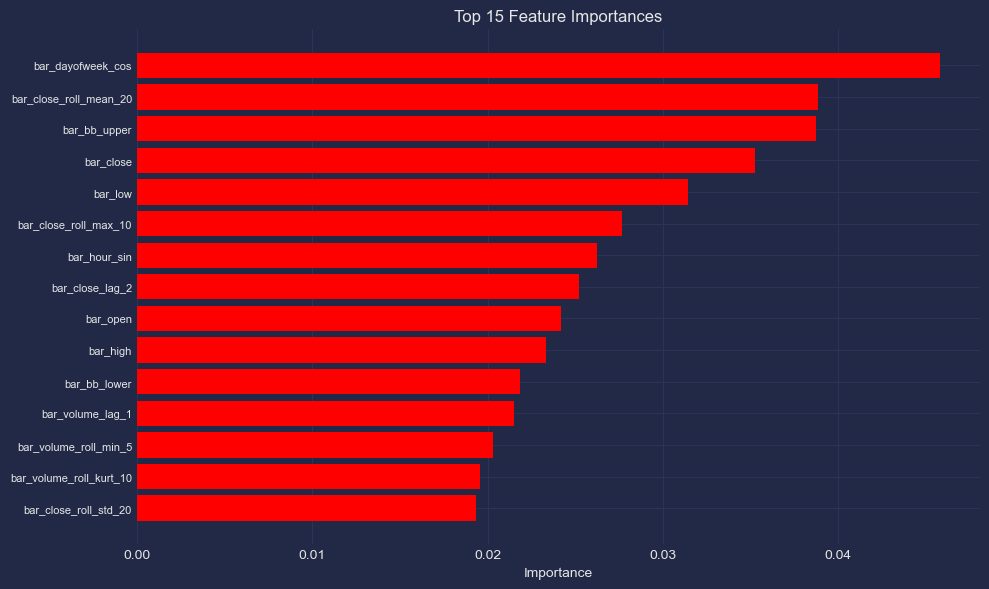


✓ Модель обучена.


In [89]:
"""
Ячейка 3 (исправленная): Генерация признаков + XGBoost
=======================================================
Убираем datetime-колонки, добавляем микроструктурные признаки.
"""
TRAIN_RATIO = 0.8
print("▸ Генерация признаков...")

# Приводим колонки баров к нижнему регистру (ожидается feature-модулями)
bars_lower = dollar_bars.rename(columns={"OPEN": "open", "HIGH": "high", "LOW": "low", "CLOSE": "close", "VOLUME": "volume"})

# Микроструктурные признаки
mf = MicroFeatures(spread_window=20, volatility_window=20, intensity_window=20)
bars_with_micro = mf.build_all_features(bars_lower)

# Общие признаки (техиндикаторы, лаги, скользящие)
fb = FeatureBuilder(windows=[5, 10, 20], lags=[1, 2, 3], include_micro=False)
bars_featured = fb.build_all(bars_with_micro)
print(f"  Всего колонок в расширенных барах: {bars_featured.shape[1]}")

# Удаляем нечисловые колонки (datetime, строки и т.п.)
numeric_cols = bars_featured.select_dtypes(include=[np.number]).columns
bars_featured = bars_featured[numeric_cols]
print(f"  Из них числовых: {len(numeric_cols)}")

# Прикрепляем признаки к событиям
events_df = labeled.copy()
for col in bars_featured.columns:
    events_df[f"bar_{col}"] = events_df.index.map(
        lambda t: bars_featured.loc[t, col] if t in bars_featured.index else np.nan
    )

events_df = events_df.dropna()
print(f"  Событий с полными признаками: {len(events_df)}")

# Бинарные метки
mask_bin = events_df["label"] != 0
feature_cols = [c for c in events_df.columns if c.startswith("bar_")]
X = events_df[feature_cols]
y = events_df["label"]

X_bin = X.loc[mask_bin]
y_bin = y.loc[mask_bin].map({1: 1, -1: 0})

print(f"  Бинарных событий: {len(X_bin)} (UP: {y_bin.sum()}, DOWN: {len(y_bin) - y_bin.sum()})")

if len(X_bin) < 30:
    print("❌ Слишком мало событий. Увеличьте историю или настройте CUSUM.")
else:
    # Разделение train/test по времени
    split_idx = int(len(X_bin) * TRAIN_RATIO)
    X_train, X_test = X_bin.iloc[:split_idx], X_bin.iloc[split_idx:]
    y_train, y_test = y_bin.iloc[:split_idx], y_bin.iloc[split_idx:]
    print(f"  Train: {len(X_train)}, Test: {len(X_test)}")

    # Модель
    print("\n▸ Обучение XGBoost...")
    model = XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
    print(f"ROC AUC:   {roc_auc_score(y_test, y_proba):.4f}")
    # Топ-15 важных признаков
    importances = model.feature_importances_
    indices = np.argsort(importances)[-15:]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(range(len(indices)), importances[indices], color="C4")
    ax.set_yticks(range(len(indices)))
    ax.set_yticklabels([X_train.columns[i] for i in indices], fontsize=8)
    ax.set_title("Top 15 Feature Importances")
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.show()

    print("\n✓ Модель обучена.")

XGBoost        : Accuracy=0.7288, ROC AUC=0.7872
Random Forest  : Accuracy=0.8814, ROC AUC=0.8617
LightGBM       : Accuracy=0.6949, ROC AUC=0.7181
CatBoost       : Accuracy=0.7458, ROC AUC=0.6915

Сравнение моделей:
        Model  Accuracy  ROC AUC
Random Forest  0.881356 0.861702
      XGBoost  0.728814 0.787234
     LightGBM  0.694915 0.718085
     CatBoost  0.745763 0.691489


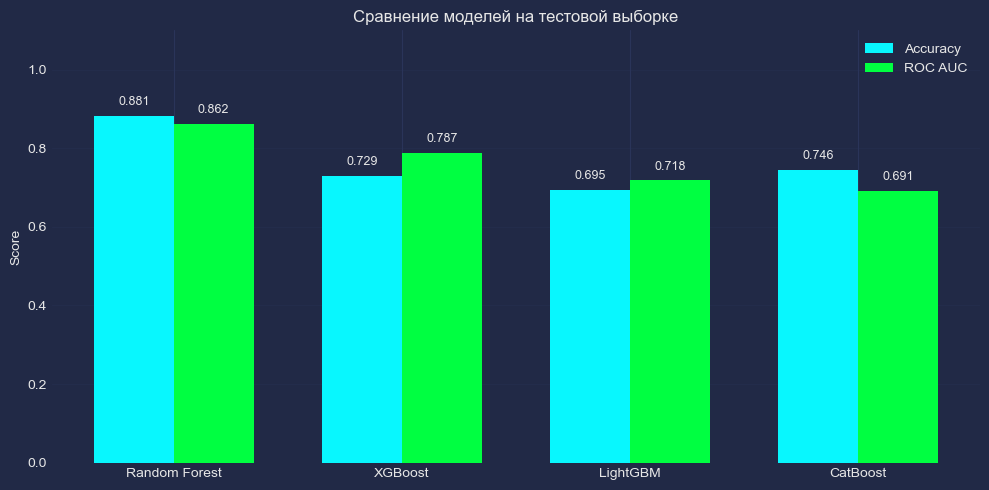

In [90]:
"""
Ячейка 4: Сравнение моделей на train/test
=========================================================
Прямое сравнение без кросс-валидации, так как данных пока мало.
"""
models = {
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=13, eval_metric="logloss", verbosity=0),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=5, random_state=13, class_weight="balanced"),
    "LightGBM": LGBMClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=13, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, depth=5, learning_rate=0.05, subsample=0.8, random_seed=13, verbose=0, allow_writing_files=False),}

results = []
for name, model in models.items():
    # Проверяем, что в y_train есть оба класса, иначе модель не обучится
    if len(np.unique(y_train)) < 2:
        print(f"{name:<15}: в обучающей выборке только один класс, пропускаем")
        continue
    # Обучаем на train
    model.fit(X_train, y_train)
    # Предсказываем на test
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    # Считаем метрики (только если в y_test есть оба класса)
    if len(np.unique(y_test)) < 2:
        acc = accuracy_score(y_test, y_pred)
        print(f"{name:<15}: Accuracy={acc:.4f} (ROC AUC не определён, только один класс в тесте)")
        results.append({"Model": name, "Accuracy": acc, "ROC AUC": np.nan})
        continue
    acc = accuracy_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_proba)
    results.append({"Model": name, "Accuracy": acc, "ROC AUC": roc})
    print(f"{name:<15}: Accuracy={acc:.4f}, ROC AUC={roc:.4f}")

df_res = pd.DataFrame(results).sort_values("ROC AUC", ascending=False)
print("\nСравнение моделей:")
print(df_res.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))    
x = np.arange(len(df_res))
width = 0.35
bars1 = ax.bar(x - width/2, df_res["Accuracy"], width, label="Accuracy", color="C6")
bars2 = ax.bar(x + width/2, df_res["ROC AUC"], width, label="ROC AUC", color="C3")
    
for bar in bars1:
    height = bar.get_height()
    if not np.isnan(height):
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9)
    
for bar in bars2:
    height = bar.get_height()
    if not np.isnan(height):
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02, f'{height:.3f}', ha='center', va='bottom', fontsize=9)
    
ax.set_ylabel("Score")
ax.set_title("Сравнение моделей на тестовой выборке")
ax.set_xticks(x)
ax.set_xticklabels(df_res["Model"])
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis='y', alpha=0.3)
    
plt.tight_layout()
plt.show()

▶ Тестирование XGBoost...
  Сделок: 57
  Доходность: 3.34%
  Win rate: 43.9%
  Sharpe: 2.28
  Max DD: -2.81%
  Profit Factor: 1.41

▶ Тестирование Random Forest...
  Сделок: 57
  Доходность: 10.38%
  Win rate: 52.6%
  Sharpe: 7.30
  Max DD: -1.15%
  Profit Factor: 3.02

▶ Тестирование LightGBM...
  Сделок: 57
  Доходность: 2.11%
  Win rate: 42.1%
  Sharpe: 1.45
  Max DD: -2.72%
  Profit Factor: 1.25

▶ Тестирование CatBoost...
  Сделок: 57
  Доходность: 2.95%
  Win rate: 43.9%
  Sharpe: 2.02
  Max DD: -2.81%
  Profit Factor: 1.36



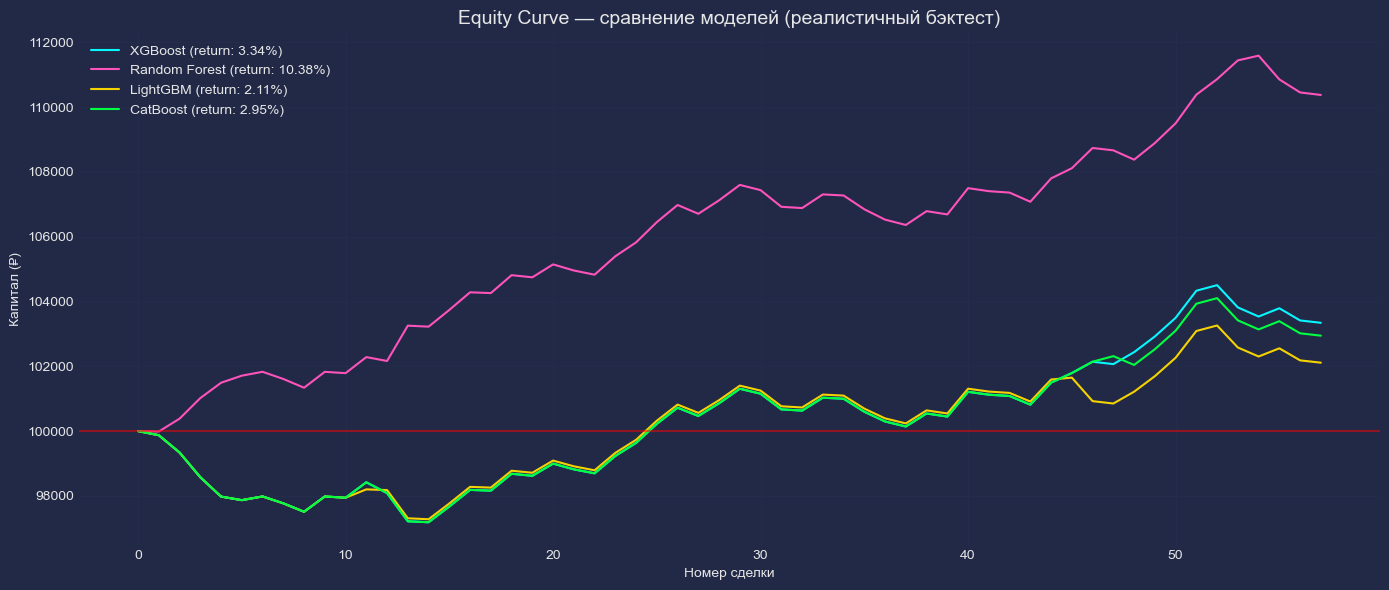


СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
       Модель  Доходность (%)   Sharpe  Max DD (%)  Win Rate (%)  Profit Factor  Сделок
      XGBoost        3.343828 2.282510   -2.813967     43.859649       1.414685      57
Random Forest       10.377862 7.300335   -1.149828     52.631579       3.022074      57
     LightGBM        2.112420 1.451516   -2.721371     42.105263       1.249618      57
     CatBoost        2.946739 2.018446   -2.813967     43.859649       1.356962      57


In [91]:
"""
Ячейка 5: Бэктест моделей (реалистичная торговая симуляция)
===============================================================
Реалистичный бэктест с учётом:
- Входа по сигналу модели
- Выхода по SL/TP (барьеры Triple Barrier)
- Выхода по смене сигнала (reverse) по рыночной цене
- Принудительного закрытия в 23:00
- Учёт комиссии и проскальзывания
- Реинвестирования прибыли
"""

models = {
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=13, eval_metric="logloss", verbosity=0),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=5, random_state=13, class_weight="balanced"),
    "LightGBM": LGBMClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=13, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, depth=5, learning_rate=0.05, subsample=0.8, random_seed=13, verbose=0, allow_writing_files=False),}

# Параметры торговли
INITIAL_CAPITAL = 100000
COMMISSION = 0.0006     # 0.06%
SLIPPAGE = 0.0001       # 0.01%

# Восстанавливаем цены
test_times = X_test.index
bar_close = dollar_bars["CLOSE"]
labeled_test = labeled.loc[test_times]

def run_backtest(model, X_train, y_train, X_test, y_test, labeled_test, bar_close,
                 initial_capital=INITIAL_CAPITAL, commission=COMMISSION, slippage=SLIPPAGE):
    """
    Реалистичный бэктест с реинвестированием.
    """
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    preds_original = np.array([-1 if p == 0 else 1 for p in preds])

    capital = initial_capital
    equity = [initial_capital]
    trades = []
    position = None  # {'side': 'long'/'short', 'entry': цена, 'entry_time': время}

    for i, (evt_time, row) in enumerate(labeled_test.iterrows()):
        signal = preds_original[i]
        if signal == 0:
            continue

        # ---- Принудительное закрытие в 23:00 ----
        if position is not None and evt_time.hour >= 23:
            close_price = bar_close.loc[evt_time]
            if position['side'] == 'long':
                pnl_pct = (close_price / position['entry'] - 1) - commission
            else:
                pnl_pct = (position['entry'] / close_price - 1) - commission
            pnl = pnl_pct * capital
            capital += pnl
            trades.append({
                'entry_time': position['entry_time'],
                'exit_time': evt_time,
                'side': position['side'],
                'entry': position['entry'],
                'exit': close_price,
                'pnl': pnl,
                'pnl_pct': pnl_pct,
                'exit_reason': 'forced_close_23'
            })
            equity.append(capital)
            position = None
            continue

        # ---- Если позиция открыта и сигнал сменился (reverse) ----
        if position is not None and signal != (1 if position['side'] == 'long' else -1):
            close_price = bar_close.loc[evt_time]
            if position['side'] == 'long':
                pnl_pct = (close_price / position['entry'] - 1) - commission
            else:
                pnl_pct = (position['entry'] / close_price - 1) - commission
            pnl = pnl_pct * capital
            capital += pnl
            trades.append({
                'entry_time': position['entry_time'],
                'exit_time': evt_time,
                'side': position['side'],
                'entry': position['entry'],
                'exit': close_price,
                'pnl': pnl,
                'pnl_pct': pnl_pct,
                'exit_reason': 'reverse_signal'
            })
            equity.append(capital)
            position = None

        # ---- Если позиция открыта и достигнут барьер SL/TP ----
        if position is not None:
            exit_type = row.get('exit_type')
            if exit_type in ('upper', 'lower', 'vertical'):
                close_price = row['exit_price']
                if position['side'] == 'long':
                    pnl_pct = (close_price / position['entry'] - 1) - commission
                else:
                    pnl_pct = (position['entry'] / close_price - 1) - commission
                pnl = pnl_pct * capital
                capital += pnl
                trades.append({
                    'entry_time': position['entry_time'],
                    'exit_time': row['exit_time'],
                    'side': position['side'],
                    'entry': position['entry'],
                    'exit': close_price,
                    'pnl': pnl,
                    'pnl_pct': pnl_pct,
                    'exit_reason': exit_type
                })
                equity.append(capital)
                position = None

        # ---- Открытие новой позиции ----
        if position is None and evt_time.hour < 21:
            entry_price = bar_close.loc[evt_time]
            # Учитываем проскальзывание при входе
            if signal == 1:
                entry_price *= (1 + slippage)
                side = 'long'
            else:
                entry_price *= (1 - slippage)  # для short цена входа выше
                side = 'short'
            position = {
                'side': side,
                'entry': entry_price,
                'entry_time': evt_time
            }

    # ---- Закрываем последнюю позицию ----
    if position is not None:
        last_row = labeled_test.iloc[-1]
        close_price = bar_close.loc[last_row.name]
        if position['side'] == 'long':
            pnl_pct = (close_price / position['entry'] - 1) - commission
        else:
            pnl_pct = (position['entry'] / close_price - 1) - commission
        pnl = pnl_pct * capital
        capital += pnl
        trades.append({
            'entry_time': position['entry_time'],
            'exit_time': last_row.name,
            'side': position['side'],
            'entry': position['entry'],
            'exit': close_price,
            'pnl': pnl,
            'pnl_pct': pnl_pct,
            'exit_reason': 'last'
        })
        equity.append(capital)

    # ---- Расчёт метрик ----
    if trades:
        df_trades = pd.DataFrame(trades)
        total_return = (capital / initial_capital - 1) * 100
        returns = df_trades['pnl_pct']
        sharpe = (returns.mean() / returns.std() * np.sqrt(252)) if returns.std() != 0 else 0
        equity_curve = np.array(equity)
        peak = np.maximum.accumulate(equity_curve)
        drawdown = (equity_curve - peak) / peak
        max_drawdown = drawdown.min() * 100
        win_rate = (df_trades['pnl'] > 0).mean() * 100
        profit_factor = (df_trades[df_trades['pnl'] > 0]['pnl'].sum() /
                         abs(df_trades[df_trades['pnl'] < 0]['pnl'].sum())) if (df_trades['pnl'] < 0).any() else np.inf
        df_trades['trade_num'] = range(1, len(df_trades) + 1)
    else:
        total_return = 0
        sharpe = 0
        max_drawdown = 0
        win_rate = 0
        profit_factor = 0
        df_trades = pd.DataFrame()
        equity_curve = np.array([initial_capital])

    return {
        'total_return': total_return,
        'sharpe': sharpe,
        'max_drawdown': max_drawdown,
        'win_rate': win_rate,
        'profit_factor': profit_factor,
        'trades': df_trades,
        'equity_curve': equity_curve
    }


# ---- Запуск бэктеста для всех моделей ----
backtest_results = {}

for name, model in models.items():
    print(f"▶ Тестирование {name}...")
    result = run_backtest(
        model, X_train, y_train, X_test, y_test,
        labeled_test, bar_close
    )
    backtest_results[name] = result

    if not result['trades'].empty:
        df_trades = result['trades']
        print(f"  Сделок: {len(df_trades)}")
        print(f"  Доходность: {result['total_return']:.2f}%")
        print(f"  Win rate: {result['win_rate']:.1f}%")
        print(f"  Sharpe: {result['sharpe']:.2f}")
        print(f"  Max DD: {result['max_drawdown']:.2f}%")
        print(f"  Profit Factor: {result['profit_factor']:.2f}")
    else:
        print("  ❌ Нет сделок")
    print()

# ---- График Equity кривых ----
fig, ax = plt.subplots(figsize=(14, 6))

for name, res in backtest_results.items():
    if res['total_return'] != 0:
        ax.plot(res['equity_curve'], label=f"{name} (return: {res['total_return']:.2f}%)")

ax.axhline(y=INITIAL_CAPITAL, color='C4', alpha=0.5)
ax.set_title("Equity Curve — сравнение моделей (реалистичный бэктест)", fontsize=14)
ax.set_xlabel("Номер сделки")
ax.set_ylabel("Капитал (₽)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ---- Итоговая таблица ----
print("\n" + "="*70)
print("СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ")
print("="*70)
summary = pd.DataFrame({
    'Модель': list(backtest_results.keys()),
    'Доходность (%)': [res['total_return'] for res in backtest_results.values()],
    'Sharpe': [res['sharpe'] for res in backtest_results.values()],
    'Max DD (%)': [res['max_drawdown'] for res in backtest_results.values()],
    'Win Rate (%)': [res['win_rate'] for res in backtest_results.values()],
    'Profit Factor': [res['profit_factor'] for res in backtest_results.values()],
    'Сделок': [len(res['trades']) for res in backtest_results.values()]
})
print(summary.to_string(index=False))

# Оптимизация

In [ ]:
# ========================== НАСТРОЙКИ ==========================
N_TRIALS = 2            # для начала можно 50-100
STUDY_NAME = "param_optimization_sharpe_v4"
TIMEOUT = 10800
TRAIN_RATIO = 0.8

# ========================== ФУНКЦИЯ ОЦЕНКИ ==========================
def objective(trial):
    dollar_threshold = trial.suggest_int('dollar_threshold', 3, 10) * 1_000_000
    pt_sl = trial.suggest_float('pt_sl', 0.3, 2.0, step=0.1)
    cusum_threshold = trial.suggest_float('cusum_threshold', 0.001, 0.005, step=0.0005)
    vertical_barrier = trial.suggest_int('vertical_barrier', 10, 50, step=5)
    target_window = trial.suggest_int('target_window', 25, 75, step=5)

    # Подготовка trades
    trades_prep = trades.copy()
    col_map = {}
    for col in trades_prep.columns:
        if col.upper() in ["PRICE", "TRADEPRICE"]:
            col_map[col] = "price"
        elif col.upper() in ["QUANTITY", "VOLUME"]:
            col_map[col] = "quantity"
    if col_map:
        trades_prep = trades_prep.rename(columns=col_map)
    trades_prep["ts"] = pd.to_datetime(trades_prep["ts"])
    trades_prep = trades_prep.dropna(subset=["price", "quantity"])

    try:
        # 1. Долларовые бары
        bar_builder = InformationDrivenBars()
        dollar_bars = bar_builder.build_dollar(trades_prep, threshold=dollar_threshold)
        if len(dollar_bars) < 20:
            return -np.inf

        dollar_bars["ts"] = dollar_bars["close_time"]
        dollar_bars["ts"] = pd.to_datetime(dollar_bars["ts"])
        if dollar_bars["ts"].dt.tz is None:
            dollar_bars["ts"] = dollar_bars["ts"].dt.tz_localize('Europe/Moscow')
        dollar_bars = dollar_bars.set_index("ts").sort_index()
        dollar_bars = dollar_bars.rename(columns={
            "open": "OPEN", "high": "HIGH", "low": "LOW",
            "close": "CLOSE", "volume": "VOLUME"
        })

        # === ГАРАНТИЯ УНИКАЛЬНОСТИ ИНДЕКСА ===
        dollar_bars = dollar_bars[~dollar_bars.index.duplicated(keep='first')]
        dollar_bars = dollar_bars[~dollar_bars.index.isna()]

        # 2. CUSUM фильтр
        events_idx = cusum_filter(dollar_bars["CLOSE"], threshold=cusum_threshold)
        if len(events_idx) == 0:
            return -np.inf

        # ===== ИСПРАВЛЕННЫЙ БЛОК СОГЛАСОВАНИЯ ТАЙМЗОН И ПРИВЯЗКИ =====
        # Приводим таймзоны
        if dollar_bars.index.tz is not None:
            if events_idx.tz is None:
                events_idx = events_idx.tz_localize(dollar_bars.index.tz)
            elif events_idx.tz != dollar_bars.index.tz:
                events_idx = events_idx.tz_convert(dollar_bars.index.tz)
        else:
            if events_idx.tz is not None:
                events_idx = events_idx.tz_localize(None)

        # Удаляем дубликаты событий
        events_idx = events_idx[~events_idx.duplicated()]

        # Привязываем к ближайшим барам
        pos = dollar_bars.index.get_indexer(events_idx, method="nearest")
        events_idx = dollar_bars.index[pos]

        # Удаляем дубликаты после привязки
        events_idx = events_idx[~events_idx.duplicated()]

        # Сортируем
        events_idx = events_idx.sort_values()

        if len(events_idx) < 5:
            return -np.inf

        # 3. Triple Barrier
        labeled = triple_barrier_labeling(
            bars=dollar_bars,
            events=events_idx,
            pt_sl=(pt_sl, pt_sl),
            vertical_barrier=vertical_barrier,
            target_window=target_window,
            target_method="ewm",
        )

        if len(labeled) < 30:
            return -np.inf

        # 4. Признаки
        bars_lower = dollar_bars.rename(columns={
            "OPEN": "open", "HIGH": "high", "LOW": "low",
            "CLOSE": "close", "VOLUME": "volume"
        })
        mf = MicroFeatures(spread_window=20, volatility_window=20, intensity_window=20)
        bars_with_micro = mf.build_all_features(bars_lower)
        fb = FeatureBuilder(windows=[5, 10, 20], lags=[1, 2, 3], include_micro=False)
        bars_featured = fb.build_all(bars_with_micro)

        numeric_cols = bars_featured.select_dtypes(include=[np.number]).columns
        bars_featured = bars_featured[numeric_cols]

        events_df = labeled.copy()
        bars_at_events = bars_featured.reindex(events_df.index)
        bars_at_events.columns = [f"bar_{col}" for col in bars_at_events.columns]
        events_df = pd.concat([events_df, bars_at_events], axis=1)
        events_df = events_df.dropna()

        if len(events_df) < 30:
            return -np.inf

        # Бинарные метки
        mask_bin = events_df["label"] != 0
        feature_cols = [c for c in events_df.columns if c.startswith("bar_")]
        X = events_df[feature_cols]
        y = events_df["label"]
        X_bin = X.loc[mask_bin]
        y_bin = y.loc[mask_bin].map({1: 1, -1: 0})

        if len(X_bin) < 30:
            return -np.inf

        # 5. Разделение train/test
        split_idx = int(len(X_bin) * TRAIN_RATIO)
        X_train, X_test = X_bin.iloc[:split_idx], X_bin.iloc[split_idx:]
        y_train, y_test = y_bin.iloc[:split_idx], y_bin.iloc[split_idx:]

        # 6. RandomForest (упрощённый)
        model = RandomForestClassifier(
            n_estimators=50,
            max_depth=3,
            random_state=13,
            class_weight="balanced",
            n_jobs=-1,
            min_samples_leaf=5
        )
        model.fit(X_train, y_train)

        # 7. Бэктест
        result = run_backtest(
            model, X_train, y_train, X_test, y_test,
            labeled.loc[X_test.index], dollar_bars["CLOSE"]
        )

        sharpe = result['sharpe'] if not np.isnan(result['sharpe']) else -np.inf

        trial.set_user_attr('total_return', result['total_return'])
        trial.set_user_attr('max_drawdown', result['max_drawdown'])
        trial.set_user_attr('win_rate', result['win_rate'])
        trial.set_user_attr('n_trades', len(result['trades']))

        return sharpe

    except Exception as e:
        # Для отладки можно выводить ошибку
        # print(f"\n[Ошибка] {e}")
        return -np.inf


# ========================== ЗАПУСК ==========================
print("="*80)
print("ОПТИМИЗАЦИЯ ПАРАМЕТРОВ (v4)")
print("="*80)
print(f"Модель: RandomForest {TICKER}")
print(f"Испытаний: {N_TRIALS}, таймаут: {TIMEOUT} сек")
print("="*80)

study = optuna.create_study(
    direction="maximize",
    study_name=STUDY_NAME,
    sampler=optuna.samplers.TPESampler(seed=13),
)

optuna.logging.set_verbosity(optuna.logging.WARNING)

with tqdm(total=N_TRIALS, desc="Оптимизация") as pbar:
    def callback(study, trial):
        pbar.update(1)
        if trial.value > -np.inf:
            pbar.set_postfix({
                'Sharpe': f'{study.best_value:.3f}',
                'Dollar': f'{study.best_params["dollar_threshold"]}M'
            })

    study.optimize(
        objective,
        n_trials=N_TRIALS,
        timeout=TIMEOUT,
        callbacks=[callback],
        show_progress_bar=False
    )

# ========================== ИТОГИ ==========================
if study.best_value > -np.inf:
    best_params = study.best_params
    best_trial = study.best_trial

    print("\n" + "="*80)
    print(f"✅ ЛУЧШИЕ ПАРАМЕТРЫ для {TICKER}")
    print("="*80)
    print(f"DOLLAR_THRESHOLD = {best_params['dollar_threshold'] * 1_000_000:,}")
    print(f"PT_SL = {best_params['pt_sl']:.1f}%")
    print(f"CUSUM_THRESHOLD = {best_params['cusum_threshold']:.4f}")
    print(f"VERTICAL_BARRIER = {best_params['vertical_barrier']}")
    print(f"TARGET_WINDOW = {best_params['target_window']}")
    print(f"\nSharpe Ratio: {best_trial.value:.3f}")

    tr = best_trial.user_attrs.get('total_return')
    if tr is not None:
        print(f"Доходность: {tr:.2f}%")
    dd = best_trial.user_attrs.get('max_drawdown')
    if dd is not None:
        print(f"Max Drawdown: {dd:.2f}%")
    wr = best_trial.user_attrs.get('win_rate')
    if wr is not None:
        print(f"Win Rate: {wr:.1f}%")
    nt = best_trial.user_attrs.get('n_trades')
    if nt is not None:
        print(f"Сделок: {nt}")
else:
    print("\n❌ Оптимизация не нашла валидных параметров!")

ОПТИМИЗАЦИЯ ПАРАМЕТРОВ (v4)
Модель: RandomForest ROSN
Испытаний: 2, таймаут: 10800 сек


Оптимизация: 100%|███████████████████████████████████████████████████████████████████████| 2/2 [00:13<00:00,  6.61s/it]


❌ Оптимизация не нашла валидных параметров!


✅ ЛУЧШИЕ ПАРАМЕТРЫ SMLT

- DOLLAR_THRESHOLD = 10,000,000
- PT_SL = 2.0%
- CUSUM_THRESHOLD = 0.0020
- VERTICAL_BARRIER = 50
- TARGET_WINDOW = 45

- Sharpe Ratio: 29.084
- Доходность: 270.55%
- Max Drawdown: -0.48%
- Win Rate: 97.9%
- Сделок: 94
- Mодель: RandomForest

✅ ЛУЧШИЕ ПАРАМЕТРЫ для GAZP

- DOLLAR_THRESHOLD = 4,000,000
- PT_SL = 2.0%
- CUSUM_THRESHOLD = 0.0025
- VERTICAL_BARRIER = 35
- TARGET_WINDOW = 65

- Sharpe Ratio: 25.927
- Доходность: 27.33%
- Max Drawdown: -0.07%
- Win Rate: 95.5%
- Сделок: 22
- Mодель: RandomForest

✅ ЛУЧШИЕ ПАРАМЕТРЫ для YDEX
- DOLLAR_THRESHOLD = 10,000,000
- PT_SL = 1.3%
- CUSUM_THRESHOLD = 0.0010
- VERTICAL_BARRIER = 50
- TARGET_WINDOW = 75

- Sharpe Ratio: 22.796
- Доходность: 36.35%
- Max Drawdown: -0.36%
- Win Rate: 93.7%
- Сделок: 63

✅ ЛУЧШИЕ ПАРАМЕТРЫ для LKOH
- DOLLAR_THRESHOLD = 10,000,000
- PT_SL = 1.9%
- CUSUM_THRESHOLD = 0.0050
- VERTICAL_BARRIER = 45
- TARGET_WINDOW = 75

- Sharpe Ratio: 15.598
- Доходность: 14.07%
- Max Drawdown: -0.37%
- Win Rate: 78.6%
- Сделок: 28

✅ ЛУЧШИЕ ПАРАМЕТРЫ для SBER (ПЕРВЫЙ ДЕНЬ ОЧЕНЬ МНОГО СОБЫТИЙ - ОЧЕНЬ СТРАННАЯ ФОРМА, УДАЛИТЬ ПЕРВЫЙ ДЕНЬ И ПЕРЕОБУЧИТЬ! 200 ПОПЫТОК ХВАТИТ!)
- DOLLAR_THRESHOLD = 10,000,000
- PT_SL = 1.4%
- CUSUM_THRESHOLD = 0.0015
- VERTICAL_BARRIER = 50
- TARGET_WINDOW = 25

- Sharpe Ratio: 10.796
- Доходность: 15.26% (пиздец конечно)
- Max Drawdown: -0.96%
- Win Rate: 69.2%
- Сделок: 65


In [47]:
import joblib
import json
from pathlib import Path
from datetime import datetime

# Путь для сохранения моделей
MODELS_DIR = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Лучшие параметры из оптимизации
best_params = {
    'ticker': TICKER,
    'dollar_threshold': 10_000_000,
    'pt_sl': 2.0,
    'cusum_threshold': 0.0020,
    'vertical_barrier': 50,
    'target_window': 45,
    'train_ratio': 0.8,
    'model_type': 'RandomForest',
    'model_params': {
        'n_estimators': 200,  # для финальной модели используем полные параметры
        'max_depth': 5,
        'random_state': 13,
        'class_weight': 'balanced',
        'n_jobs': -1
    },
    'metrics': {
        'sharpe': 29.084,
        'total_return': 270.55,
        'max_drawdown': -0.48,
        'win_rate': 97.9,
        'n_trades': 94
    }
}

# ========================== ПЕРЕОБУЧЕНИЕ МОДЕЛИ ==========================
print("▸ Переобучение модели на всех данных с лучшими параметрами...")

# 1. Построение долларовых баров с оптимальным порогом
trades_prep = trades.copy()
col_map = {}
for col in trades_prep.columns:
    if col.upper() in ["PRICE", "TRADEPRICE"]:
        col_map[col] = "price"
    elif col.upper() in ["QUANTITY", "VOLUME"]:
        col_map[col] = "quantity"
if col_map:
    trades_prep = trades_prep.rename(columns=col_map)
trades_prep["ts"] = pd.to_datetime(trades_prep["ts"])
trades_prep = trades_prep.dropna(subset=["price", "quantity"])

bar_builder = InformationDrivenBars()
dollar_bars = bar_builder.build_dollar(trades_prep, threshold=best_params['dollar_threshold'])
dollar_bars["ts"] = dollar_bars["close_time"]
dollar_bars["ts"] = pd.to_datetime(dollar_bars["ts"])
if dollar_bars["ts"].dt.tz is None:
    dollar_bars["ts"] = dollar_bars["ts"].dt.tz_localize('Europe/Moscow')
dollar_bars = dollar_bars.set_index("ts").sort_index()
dollar_bars = dollar_bars.rename(columns={
    "open": "OPEN", "high": "HIGH", "low": "LOW", 
    "close": "CLOSE", "volume": "VOLUME"
})

# 2. CUSUM фильтр
events_idx = cusum_filter(dollar_bars["CLOSE"], threshold=best_params['cusum_threshold'])
if dollar_bars.index.tz is not None:
    if events_idx.tz is None:
        events_idx = events_idx.tz_localize(dollar_bars.index.tz)
    elif events_idx.tz != dollar_bars.index.tz:
        events_idx = events_idx.tz_convert(dollar_bars.index.tz)

if not events_idx.isin(dollar_bars.index).all():
    pos = dollar_bars.index.get_indexer(events_idx, method="nearest")
    events_idx = dollar_bars.index[pos]
events_idx = events_idx.sort_values().drop_duplicates()

# 3. Triple Barrier разметка
labeled = triple_barrier_labeling(
    bars=dollar_bars,
    events=events_idx,
    pt_sl=(best_params['pt_sl'], best_params['pt_sl']),
    vertical_barrier=best_params['vertical_barrier'],
    target_window=best_params['target_window'],
    target_method="ewm",
)

# 4. Генерация признаков
bars_lower = dollar_bars.rename(columns={
    "OPEN": "open", "HIGH": "high", "LOW": "low", 
    "CLOSE": "close", "VOLUME": "volume"
})
mf = MicroFeatures(spread_window=20, volatility_window=20, intensity_window=20)
bars_with_micro = mf.build_all_features(bars_lower)
fb = FeatureBuilder(windows=[5, 10, 20], lags=[1, 2, 3], include_micro=False)
bars_featured = fb.build_all(bars_with_micro)

numeric_cols = bars_featured.select_dtypes(include=[np.number]).columns
bars_featured = bars_featured[numeric_cols]

events_df = labeled.copy()
bars_at_events = bars_featured.reindex(events_df.index)
bars_at_events.columns = [f"bar_{col}" for col in bars_at_events.columns]
events_df = pd.concat([events_df, bars_at_events], axis=1)
events_df = events_df.dropna()

# Бинарные метки
mask_bin = events_df["label"] != 0
feature_cols = [c for c in events_df.columns if c.startswith("bar_")]
X = events_df[feature_cols]
y = events_df["label"]
X_bin = X.loc[mask_bin]
y_bin = y.loc[mask_bin].map({1: 1, -1: 0})

# 5. Обучение финальной модели на ВСЕХ данных
final_model = RandomForestClassifier(
    n_estimators=200,  # полные параметры для финальной модели
    max_depth=5,
    random_state=13,
    class_weight="balanced",
    n_jobs=-1
)
final_model.fit(X_bin, y_bin)

# ========================== СОХРАНЕНИЕ ==========================
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Сохраняем модель
model_filename = f"{TICKER}_RandomForest_best_{timestamp}.pkl"
model_path = MODELS_DIR / model_filename
joblib.dump(final_model, model_path)

# Сохраняем параметры
params_filename = f"{TICKER}_params_{timestamp}.json"
params_path = MODELS_DIR / params_filename
with open(params_path, 'w', encoding='utf-8') as f:
    json.dump(best_params, f, indent=4, ensure_ascii=False)

# Сохраняем список признаков
features_filename = f"{TICKER}_features_{timestamp}.json"
features_path = MODELS_DIR / features_filename
with open(features_path, 'w', encoding='utf-8') as f:
    json.dump({'features': list(feature_cols)}, f, indent=4)

print(f"\n✅ Модель сохранена: {model_path}")
print(f"✅ Параметры сохранены: {params_path}")
print(f"✅ Список признаков сохранен: {features_path}")
print(f"\nРазмер модели: {model_path.stat().st_size / 1024 / 1024:.2f} MB")
print(f"Количество признаков: {len(feature_cols)}")
print(f"Обучена на {len(X_bin)} событиях")

▸ Переобучение модели на всех данных с лучшими параметрами...

✅ Модель сохранена: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\models\YDEX_RandomForest_best_20260819_171648.pkl
✅ Параметры сохранены: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\models\YDEX_params_20260819_171648.json
✅ Список признаков сохранен: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\models\YDEX_features_20260819_171648.json

Размер модели: 0.57 MB
Количество признаков: 73
Обучена на 203 событиях
